# Parametric 3D CAD Model Generation (`kaleidocycle.cad`)

This notebook demonstrates how to generate 3D-printable **Twisted Plate** Kaleidocycle parts and assemblies using the optional `build123d` backend (`kaleidocycle.cad`).

The geometry is parameterized by:
- `torsion_angle`: twist angle between the two hinge axes (radians by default, or degrees with `degrees=True`)
- `ribbon_width`: length along each hinge axis (mm; default 43)
- `edge_length`: center-to-center distance between bottom and top hinge axes (mm)
- `with_ring`: whether to include the captive print-in-place ring (`False` by default)
- Additional hinge and clearance parameters (`body_thickness`, `hinge_diameter`, `hinge_gap`, `gap`, `num_knuckles`, etc.)
- `hinge_type`: `"pin"` (separate octagonal pins, default) or `"cone"` (snap-in cone pivots)
- Hinge fit (`pin_diameter`, `pin_fit_clearance`, `pin_clearance`, `pin_core_diameter`, `pin_chamfer`; `cone_diameter`, `cone_angle`, `snap_gap`)

Both hinge types reproduce NovemberKou's printed designs:
- `hinge_type="pin"` (*Material-saving Design*): separately printed octagonal hinge pins. The bottom knuckles of a unit hold the pin (bore radius equal to the pin's corner radius, a light press fit that does not wobble), and the top knuckles of the neighbouring unit rotate on it (0.2 mm radial clearance).
- `hinge_type="cone"` (*Twisted Plate with Ring*): no separate parts. The outer bottom knuckles carry 60° cones that snap into conical sockets in the neighbour's outer top knuckles; the socketed knuckles keep a 2.25 mm gap on their inner side so they can flex past the cone tips.

Every export checks the parts for contacts automatically (`kaleidocycle.cad_check`): the hinge fit, and for a kaleidocycle every pair of links through a full rotation (traced with the integrable flow). Contacts closer than `min_clearance` (0.4 mm) raise a `ClearanceWarning`.

In [1]:
%matplotlib widget

import struct
from pathlib import Path

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import numpy as np

from kaleidocycle import (
    Kaleidocycle,
    TwistedPlateConfig,
    build_twisted_plate_parts,
    check_kaleidocycle_clearance,
    critical_torsion_cosine,
    export_print_plate,
    export_twisted_plate,
    framed_polygon_from_binormals,
    twisted_plate_from_kaleidocycle,
    variational_recurrence_residual,
)

output_dir = (
    Path("output")
    if Path.cwd().name == "notebooks"
    else Path("notebooks/output")
)
output_dir.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {output_dir.resolve()}")

Output directory: /Users/kaji/Library/CloudStorage/Dropbox/maple/Kaleidocycle/python/notebooks/output


## 1. $N=7$ Anti-Oriented Critical Torsion Kaleidocycle

We construct an anti-oriented (`oriented=False`, monodromy `sign=-1`) $N=7$ Möbius Kaleidocycle and inspect its constant torsion angle and variational critical-torsion diagnostics.

/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/scipy/optimize/_trustregion_constr/equality_constrained_sqp.py:81: UserWarning: Singular Jacobian matrix. Using SVD decomposition to perform the factorizations.
  Z, LS, Y = projections(A, factorization_method)
/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/scipy/optimize/_differentiable_functions.py:737: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(delta_x, delta_g)
/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/scipy/optimize/_trustregion_constr/equality_constrained_sqp.py:217: UserWarning: Singular Jacobian matrix. Using SVD decomposition to perform the factorizations.
  Z, LS, Y = projections(A, factorization_method)


n                    : 7
oriented / sign      : False / -1
constant_torsion     : 1.2709341213 rad (72.819161 deg)
cos(torsion)         : 0.2953885638
critical_torsion_cos : 0.2953881039 (72.819189 deg)
recurrence residual  : 3.813e-06
is_closed / aligned  : True / True


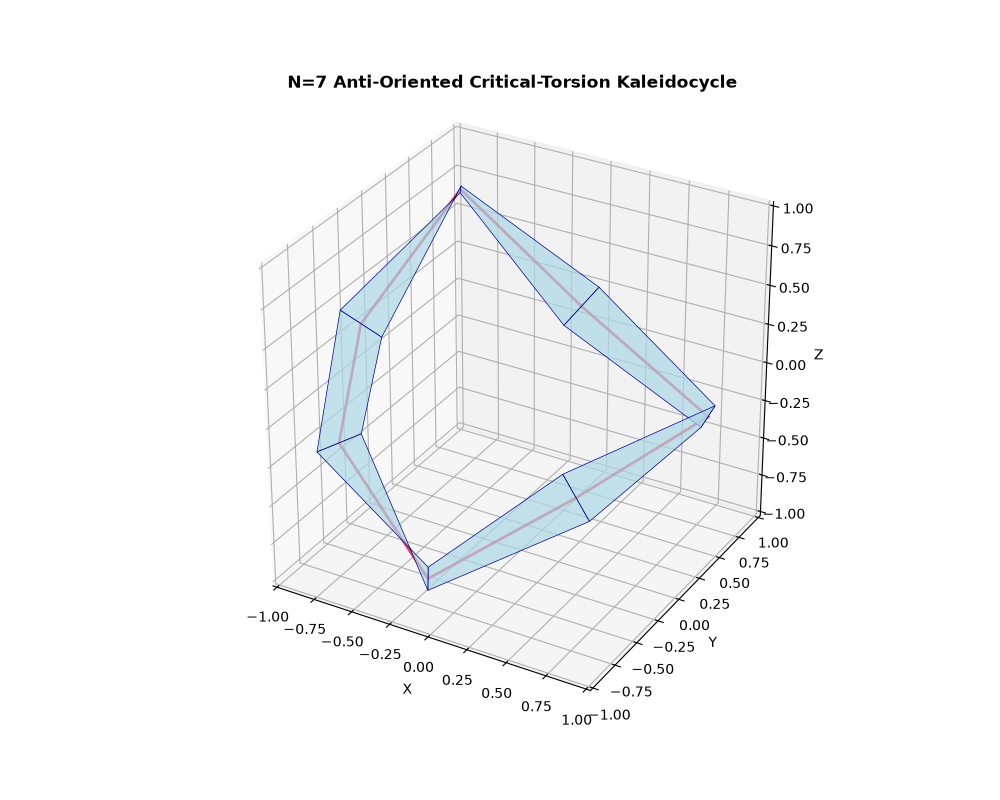

In [2]:
kc7 = Kaleidocycle(7, oriented=False, seed=42)
fp7 = framed_polygon_from_binormals(kc7.hinges)

cos_mean = float(np.mean(np.sum(kc7.hinges[:-1] * kc7.hinges[1:], axis=1)))
c_crit = critical_torsion_cosine(fp7.curvatures, sign=fp7.sign)
rec_norm = float(
    np.linalg.norm(variational_recurrence_residual(fp7.curvatures, sign=fp7.sign))
)

print(f"n                    : {kc7.n}")
print(f"oriented / sign      : {kc7.oriented} / {fp7.sign}")
print(
    f"constant_torsion     : {kc7.constant_torsion:.10f} rad "
    f"({np.rad2deg(kc7.constant_torsion):.6f} deg)"
)
print(f"cos(torsion)         : {cos_mean:.10f}")
print(
    f"critical_torsion_cos : {c_crit:.10f} "
    f"({np.rad2deg(np.arccos(c_crit)):.6f} deg)"
)
print(f"recurrence residual  : {rec_norm:.3e}")
print(f"is_closed / aligned  : {kc7.is_closed} / {kc7.is_aligned}")

ax = kc7.plot(
    title="N=7 Anti-Oriented Critical-Torsion Kaleidocycle",
    show_curve=True,
)
plt.show()

## 2. Export 3D Printable Models for $N=7$ Anti-Oriented Critical Torsion

Using `twisted_plate_from_kaleidocycle()` and `export_print_plate()`, we convert the $N=7$ anti-oriented critical torsion into 3D-printable outputs:
- Single twisted-plate unit without ring (`.stl`, `.step`)
- Single twisted-plate unit with captive ring (`.stl`, `.step`, `.3mf`)
- 7-unit simultaneous print plates without/with ring (`.3mf` + `.stl` layout preview)
- Full 7-unit closed 3D assembly (`.stl`, `.step`)
- 7-unit print plates with snap-in cone hinges (`.3mf`)

The `.3mf` files are plain 3MF (core specification) without slicer project settings: Bambu Studio, OrcaSlicer, and PrusaSlicer open them as geometry and keep the printer, filament, and process presets you currently have selected. Each unit is one object (with `plate` and `ring` parts when `with_ring=True`), laid out around the centre of a 256 mm bed (`bed_center=(128, 128)` by default).

Print plates also carry one hinge pin per unit (object `hinge_pin`, lying flat so that it prints without support), and the assembly shows the pins in place. Push each pin through the bottom knuckles of one unit and the interleaved top knuckles of the next; the chamfered ends ease insertion.

The ribbon is 43 mm wide: at 45 mm, links two apart graze each other near the centre of the ring during the rotation (see the clearance reports below).

In [3]:
cfg_k7 = twisted_plate_from_kaleidocycle(
    kc7,
    ribbon_width=43.0,
    edge_length=29.0,
    with_ring=False,
)
print(cfg_k7)
print(f"torsion_degrees = {cfg_k7.torsion_degrees:.6f} deg")

exported_files = [
    export_twisted_plate(output_dir / "k7_anti_oriented_unit.stl", cfg_k7),
    export_twisted_plate(output_dir / "k7_anti_oriented_unit.step", cfg_k7),
    export_twisted_plate(
        output_dir / "k7_anti_oriented_unit_with_ring.stl",
        cfg_k7,
        with_ring=True,
    ),
    export_twisted_plate(
        output_dir / "k7_anti_oriented_unit_with_ring.step",
        cfg_k7,
        with_ring=True,
    ),
    export_twisted_plate(
        output_dir / "k7_anti_oriented_unit_with_ring.3mf",
        cfg_k7,
        with_ring=True,
    ),
    kc7.export_twisted_plate(
        output_dir / "k7_anti_oriented_plate.3mf",
        ribbon_width=43.0,
        edge_length=29.0,
        with_ring=False,
    ),
    kc7.export_twisted_plate(
        output_dir / "k7_anti_oriented_plate_with_ring.3mf",
        ribbon_width=43.0,
        edge_length=29.0,
        with_ring=True,
    ),
    export_print_plate(
        output_dir / "k7_anti_oriented_plate.stl",
        kc7,
        ribbon_width=43.0,
        edge_length=29.0,
        with_ring=False,
    ),
    kc7.export_twisted_plate(
        output_dir / "k7_anti_oriented_assembly.stl",
        ribbon_width=43.0,
        edge_length=29.0,
        assembly=True,
    ),
    kc7.export_twisted_plate(
        output_dir / "k7_anti_oriented_assembly.step",
        ribbon_width=43.0,
        edge_length=29.0,
        assembly=True,
    ),
    kc7.export_twisted_plate(
        output_dir / "k7_anti_oriented_plate_cone.3mf",
        ribbon_width=43.0,
        edge_length=29.0,
        hinge_type="cone",
    ),
    kc7.export_twisted_plate(
        output_dir / "k7_anti_oriented_plate_cone_with_ring.3mf",
        ribbon_width=43.0,
        edge_length=29.0,
        with_ring=True,
        hinge_type="cone",
    ),
    kc7.export_twisted_plate(
        output_dir / "k7_anti_oriented_assembly_cone.stl",
        ribbon_width=43.0,
        edge_length=29.0,
        assembly=True,
        hinge_type="cone",
    ),
]

for path in exported_files:
    print(f"Exported {path.name:40s} ({path.stat().st_size:,} bytes)")

TwistedPlateConfig(torsion_angle=1.270934121274113, ribbon_width=43.0, edge_length=29.0, body_thickness=1.8, hinge_type='pin', hinge_diameter=None, hinge_gap=0.2, gap=0.2, num_knuckles=5, pin_diameter=4.0, pin_fit_clearance=0.0, pin_clearance=0.2, pin_core_diameter=1.8, pin_chamfer=0.5, cone_diameter=4.0, cone_angle=60.0, snap_gap=2.25, with_ring=False, cut_slits=None, ring_diameter=None, ring_width=2.0, ring_gap=0.5, slit_rail_height=2.0, loft_slices=25)
torsion_degrees = 72.819161 deg


Exported k7_anti_oriented_unit.stl                (407,984 bytes)
Exported k7_anti_oriented_unit.step               (300,903 bytes)
Exported k7_anti_oriented_unit_with_ring.stl      (501,784 bytes)
Exported k7_anti_oriented_unit_with_ring.step     (416,991 bytes)
Exported k7_anti_oriented_unit_with_ring.3mf      (128,713 bytes)
Exported k7_anti_oriented_plate.3mf               (110,245 bytes)
Exported k7_anti_oriented_plate_with_ring.3mf     (128,814 bytes)
Exported k7_anti_oriented_plate.stl               (3,089,084 bytes)
Exported k7_anti_oriented_assembly.stl            (3,143,484 bytes)
Exported k7_anti_oriented_assembly.step           (3,030,014 bytes)
Exported k7_anti_oriented_plate_cone.3mf          (118,588 bytes)
Exported k7_anti_oriented_plate_cone_with_ring.3mf (137,702 bytes)
Exported k7_anti_oriented_assembly_cone.stl       (3,452,684 bytes)


In [4]:
print(
    f"hinge pin      : octagon {cfg_k7.pin_diameter:.2f} mm corner-to-corner, "
    f"{2 * cfg_k7.pin_inradius:.2f} mm across flats, {cfg_k7.ribbon_width:.1f} mm long"
)
print(f"bottom knuckles: bore r = {cfg_k7.fixed_bore_radius:.2f} mm (hold the pin)")
print(f"top knuckles   : bore r = {cfg_k7.free_bore_radius:.2f} mm (rotate on the pin)")
print(
    f"knuckle / gaps : diameter {cfg_k7.resolved_hinge_diameter:.1f} mm, "
    f"axial gap {cfg_k7.hinge_gap:.1f} mm"
)

cfg_cone = TwistedPlateConfig(**{**cfg_k7.__dict__, "hinge_type": "cone"})
print(
    f"cone hinge     : {cfg_cone.cone_diameter:.1f} mm base, {cfg_cone.cone_angle:.0f} deg "
    f"half-angle, {cfg_cone.cone_height:.3f} mm high; knuckles "
    f"{cfg_cone.resolved_hinge_diameter:.1f} mm; snap deflection "
    f"{cfg_cone.snap_deflection:.2f} mm into a {cfg_cone.snap_gap:.2f} mm gap"
)

hinge pin      : octagon 4.00 mm corner-to-corner, 3.70 mm across flats, 43.0 mm long
bottom knuckles: bore r = 2.00 mm (hold the pin)
top knuckles   : bore r = 2.20 mm (rotate on the pin)
knuckle / gaps : diameter 7.0 mm, axial gap 0.2 mm
cone hinge     : 4.0 mm base, 60 deg half-angle, 1.155 mm high; knuckles 6.0 mm; snap deflection 0.95 mm into a 2.25 mm gap


### Contact check through the rotation

`check_kaleidocycle_clearance()` (run automatically by the exports above) moves the ring of links through one full rotation and reports the smallest clearances. Below: both hinge types at 43 mm, and the 45 mm ribbon that collides.

In [5]:
for kwargs in (
    {"ribbon_width": 43.0, "hinge_type": "pin"},
    {"ribbon_width": 43.0, "hinge_type": "cone"},
    {"ribbon_width": 45.0, "hinge_type": "pin"},
):
    report = check_kaleidocycle_clearance(kc7, edge_length=29.0, **kwargs)
    print(f"ribbon_width={kwargs['ribbon_width']:.0f} mm")
    print(report.summary())
    print()

ribbon_width=43 mm
Clearance check (pin hinges, required 0.40 mm between non-adjacent links): OK
  motion          : mKdV2 flow, cycle of 239 steps (239 poses checked)
  hinge fit       : 0.20 mm
  adjacent links  : more than 3.0 mm (away from the hinge)
  non-adjacent    : 0.92 mm

ribbon_width=43 mm
Clearance check (cone hinges, required 0.40 mm between non-adjacent links): OK
  motion          : mKdV2 flow, cycle of 239 steps (239 poses checked)
  hinge fit       : 0.17 mm
  adjacent links  : more than 3.0 mm (away from the hinge)
  non-adjacent    : 1.05 mm



ribbon_width=45 mm
Clearance check (pin hinges, required 0.40 mm between non-adjacent links): 7 contact(s)
  motion          : mKdV2 flow, cycle of 239 steps (239 poses checked)
  hinge fit       : 0.20 mm
  adjacent links  : more than 3.0 mm (away from the hinge)
  non-adjacent    : 0.00 mm
  - non-adjacent: link 0 / link 2, overlap 0.14 mm^3 at 18% of the cycle
  - non-adjacent: link 0 / link 5, overlap 0.15 mm^3 at 10% of the cycle
  - non-adjacent: link 1 / link 3, overlap 0.57 mm^3 at 49% of the cycle
  - non-adjacent: link 1 / link 6, overlap 1.18 mm^3 at 41% of the cycle
  - non-adjacent: link 2 / link 4, overlap 1.04 mm^3 at 26% of the cycle
  - non-adjacent: link 3 / link 5, overlap 0.15 mm^3 at 7% of the cycle
  - non-adjacent: link 4 / link 6, overlap 1.17 mm^3 at 84% of the cycle



## 3. Direct Parametric Customization Examples

You can also specify `torsion_angle`, `ribbon_width`, `edge_length`, `num_knuckles`, `with_ring`, and wall/clearance parameters directly without constructing a `Kaleidocycle`.

In [6]:
custom_configs = {
    "compact_no_ring": TwistedPlateConfig(
        torsion_angle=np.deg2rad(60.0),
        ribbon_width=36.0,
        edge_length=24.0,
        body_thickness=1.6,
        num_knuckles=3,
        with_ring=False,
    ),
    "wide_with_ring": TwistedPlateConfig(
        torsion_angle=np.deg2rad(80.0),
        ribbon_width=55.0,
        edge_length=35.0,
        body_thickness=2.0,
        with_ring=True,
    ),
}

for name, cfg in custom_configs.items():
    parts = build_twisted_plate_parts(cfg)
    volumes = {k: round(v.volume, 2) for k, v in parts.items()}
    valid = {k: v.is_valid() for k, v in parts.items()}
    bbox = parts["plate"].bounding_box()
    print(
        f"{name:16s} | torsion={cfg.torsion_degrees:5.1f} deg | "
        f"W={cfg.ribbon_width:4.1f} mm | d={cfg.edge_length:4.1f} mm | "
        f"parts={volumes} mm^3 | valid={valid} | "
        f"Z=[{bbox.min.Z:.2f}, {bbox.max.Z:.2f}]"
    )

custom_stl = export_twisted_plate(
    output_dir / "custom_60deg_W36_d24.stl",
    torsion_angle=60.0,
    ribbon_width=36.0,
    edge_length=24.0,
    num_knuckles=3,
    degrees=True,
)
print(
    f"Exported custom model: {custom_stl.name} ({custom_stl.stat().st_size:,} bytes)"
)

compact_no_ring  | torsion= 60.0 deg | W=36.0 mm | d=24.0 mm | parts={'plate': 1848.7} mm^3 | valid={'plate': True} | Z=[-0.00, 30.70]


wide_with_ring   | torsion= 80.0 deg | W=55.0 mm | d=35.0 mm | parts={'plate': 4115.09, 'ring': 219.91} mm^3 | valid={'plate': True, 'ring': True} | Z=[-0.00, 41.70]


Exported custom model: custom_60deg_W36_d24.stl (312,684 bytes)


## 4. 3D Mesh Preview of Exported STL Files

Read triangles directly from the generated binary `.stl` files and inspect the unit geometry with and without the captive ring.

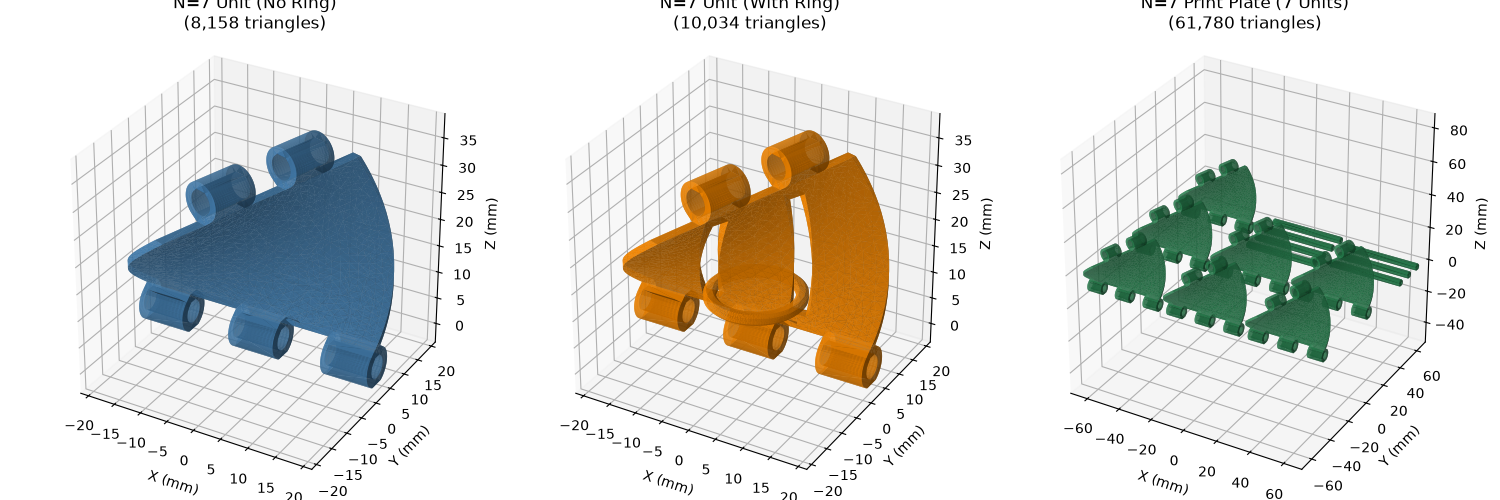

In [7]:
def load_binary_stl_triangles(path: Path) -> np.ndarray:
    data = path.read_bytes()
    n_tri = struct.unpack("<I", data[80:84])[0]
    tri_dtype = np.dtype(
        [
            ("normal", "<f4", (3,)),
            ("verts", "<f4", (3, 3)),
            ("attr", "<u2"),
        ]
    )
    records = np.frombuffer(data, dtype=tri_dtype, count=n_tri, offset=84)
    return records["verts"].astype(float)


def plot_stl_mesh(ax, path: Path, title: str, color: str = "steelblue") -> None:
    tris = load_binary_stl_triangles(path)
    coll = Poly3DCollection(
        tris,
        facecolors=color,
        alpha=0.85,
        shade=True,
    )
    ax.add_collection3d(coll)
    pts = tris.reshape(-1, 3)
    mins = pts.min(axis=0)
    maxs = pts.max(axis=0)
    center = 0.5 * (mins + maxs)
    half = 0.5 * float(np.max(maxs - mins))
    ax.set_xlim(center[0] - half, center[0] + half)
    ax.set_ylim(center[1] - half, center[1] + half)
    ax.set_zlim(center[2] - half, center[2] + half)
    ax.set_box_aspect([1, 1, 1])
    ax.set_xlabel("X (mm)")
    ax.set_ylabel("Y (mm)")
    ax.set_zlabel("Z (mm)")
    ax.set_title(f"{title}\n({len(tris):,} triangles)")


fig = plt.figure(figsize=(15, 5))
ax1 = fig.add_subplot(131, projection="3d")
plot_stl_mesh(
    ax1,
    output_dir / "k7_anti_oriented_unit.stl",
    "N=7 Unit (No Ring)",
    color="steelblue",
)
ax2 = fig.add_subplot(132, projection="3d")
plot_stl_mesh(
    ax2,
    output_dir / "k7_anti_oriented_unit_with_ring.stl",
    "N=7 Unit (With Ring)",
    color="darkorange",
)
ax3 = fig.add_subplot(133, projection="3d")
plot_stl_mesh(
    ax3,
    output_dir / "k7_anti_oriented_plate.stl",
    "N=7 Print Plate (7 Units)",
    color="seagreen",
)
plt.tight_layout()
plt.show()